# Evaluación 3: Modelo de clasificación de riesgo crediticio con `DecisionTreeClassifier`

**Autor:** Sebastian Bustos, Nicolás Parada, Genesis Parada y Jorge Rocha

**Correo Electrónico:** sebastian.bustos2301@alumnos.ubiobio.cl, nicolas.parada2301@alumnos.ubiobio.cl, genesis.parada2301@alumnos.ubiobio.cl, jorge.rocha2301@alumnos.ubiobio.cl

**Fecha de Creación:** Septiembre de 2026  
**Versión:** 1.0

---

## Descripción

Una institución financiera evalúa solicitudes de créditos hipotecarios y necesita predecir si un cliente caerá en impago (`Riesgo_Impago` = 1) o cumplirá sus pagos (`Riesgo_Impago` = 0).

Este notebook construye el pipeline completo: diagnóstico de calidad de datos, limpieza mediante `Pipeline` + `ColumnTransformer`, un modelo línea base y un modelo optimizado con `GridSearchCV` (ambos `DecisionTreeClassifier`, `random_state=29`), y su evaluación sobre el conjunto de prueba en términos financieros.

**Costos del negocio (estudios preliminares):**
- Falso Negativo (se otorga crédito a un cliente que cae en impago): **\$1.500.000**
- Falso Positivo (se deniega crédito a un cliente que habría pagado): **\$200.000**

---

## Requisitos de Software

Este notebook fue desarrollado con Python 3.12. Bibliotecas necesarias: pandas, numpy, matplotlib, seaborn y scikit-learn.

In [45]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    fbeta_score,
    make_scorer,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree

RANDOM_STATE = 29
COSTO_FN = 1_500_000  # Crédito otorgado que termina en impago
COSTO_FP = 200_000    # Crédito viable denegado

# Fase 1: Diagnóstico y calidad de datos (EDA)

In [46]:
!wget https://raw.githubusercontent.com/898jorge/EntregasIA/main/E3-Classifier/riesgo_crediticio.csv

--2026-11-02 02:55:41--  https://raw.githubusercontent.com/898jorge/EntregasIA/main/E3-Classifier/riesgo_crediticio.csv
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.109.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 953627 (931K) [text/plain]
Saving to: ‘riesgo_crediticio.csv.2’

riesgo_crediticio.c 100%[===================>] 931.28K  --.-KB/s    in 0.03s   

2026-11-02 02:55:41 (27.1 MB/s) - ‘riesgo_crediticio.csv.2’ saved [953627/953627]



In [47]:
data = pd.read_csv("riesgo_crediticio.csv")
print(f"Filas: {data.shape[0]:,} | Columnas: {data.shape[1]}")
data.head()

Filas: 25,000 | Columnas: 6


,Unnamed: 0,Ingreso_Anual,Monto_Prestamo,Puntaje_Credito,Relacion_Deuda_Ingreso,Riesgo_Impago
0,0,39785.55,85246.38,694.0,70.00,0
1,1,69773.95,244260.00,622.0,10.65,0
2,2,127770.68,209310.35,780.0,42.70,0
3,3,16799.80,213059.98,741.0,48.04,0
4,4,70229.83,219523.13,714.0,25.58,0


In [48]:
# Tipos de datos y valores nulos
data.info()
print("\nNulos por columna:")
print(data.isna().sum())
print(f"\nFilas duplicadas: {data.duplicated().sum()}")

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25000 entries, 0 to 24999
Data columns (total 6 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Unnamed: 0              25000 non-null  int64  
 1   Ingreso_Anual           25000 non-null  float64
 2   Monto_Prestamo          25000 non-null  float64
 3   Puntaje_Credito         25000 non-null  float64
 4   Relacion_Deuda_Ingreso  25000 non-null  float64
 5   Riesgo_Impago           25000 non-null  int64  
dtypes: float64(4), int64(2)
memory usage: 1.1 MB

Nulos por columna:
Unnamed: 0                0
Ingreso_Anual             0
Monto_Prestamo            0
Puntaje_Credito           0
Relacion_Deuda_Ingreso    0
Riesgo_Impago             0
dtype: int64

Filas duplicadas: 0


In [49]:
# Elimina la(s) columnas sin aporte para el modelo (índice exportado del CSV)
data.drop(["Unnamed: 0"], axis=1, inplace=True)
data.describe().T

,count,mean,std,min,25%,50%,75%,max
Ingreso_Anual,25000.0,55824.444883,29804.903177,7832.12,35051.3175,49234.685,68923.5200,348135.55
Monto_Prestamo,25000.0,220162.891849,60059.302633,50000.00,179438.0775,220241.470,261003.3625,451784.21
Puntaje_Credito,25000.0,680.033440,59.784266,457.00,640.0000,680.000,721.0000,850.00
Relacion_Deuda_Ingreso,25000.0,24.027319,13.615029,5.00,13.7875,21.450,31.3825,70.00
Riesgo_Impago,25000.0,0.071560,0.257763,0.00,0.0000,0.000,0.0000,1.00


In [50]:
# Inconsistencias lógicas
chequeos = {
    "Ingreso_Anual <= 0": (data["Ingreso_Anual"] <= 0).sum(),
    "Monto_Prestamo <= 0": (data["Monto_Prestamo"] <= 0).sum(),
    "Puntaje_Credito fuera de 300-850": (~data["Puntaje_Credito"].between(300, 850)).sum(),
    "Relacion_Deuda_Ingreso fuera de 0-100": (~data["Relacion_Deuda_Ingreso"].between(0, 100)).sum(),
    "Relacion_Deuda_Ingreso en el tope (70)": (data["Relacion_Deuda_Ingreso"] == 70).sum(),
}
pd.Series(chequeos, name="Casos")

,Casos
Ingreso_Anual <= 0,0
Monto_Prestamo <= 0,0
Puntaje_Credito fuera de 300-850,0
Relacion_Deuda_Ingreso fuera de 0-100,0
Relacion_Deuda_Ingreso en el tope (70),196


,n_outliers,%
Ingreso_Anual,976.0,3.90
Monto_Prestamo,157.0,0.63
Puntaje_Credito,167.0,0.67
Relacion_Deuda_Ingreso,663.0,2.65


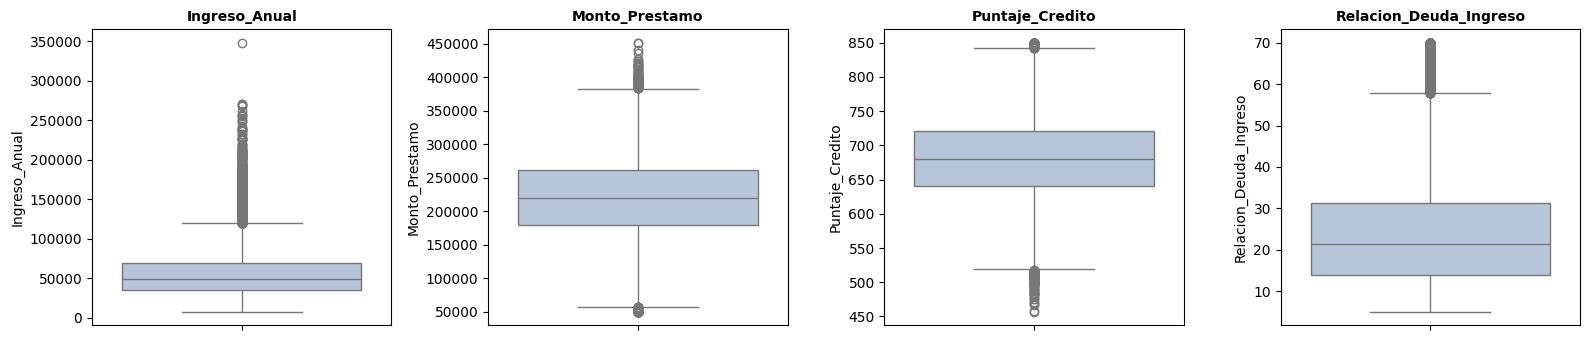

In [51]:
# Outliers por regla del rango intercuartílico (IQR)
features_num = [c for c in data.columns if c != "Riesgo_Impago"]
outliers = {}
for col in features_num:
    q1, q3 = data[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    mask = (data[col] < q1 - 1.5 * iqr) | (data[col] > q3 + 1.5 * iqr)
    outliers[col] = {"n_outliers": mask.sum(), "%": round(mask.mean() * 100, 2)}
display(pd.DataFrame(outliers).T)

fig, axes = plt.subplots(1, 4, figsize=(16, 3.5))
for ax, col in zip(axes, features_num):
    sns.boxplot(y=data[col], ax=ax, color="lightsteelblue")
    ax.set_title(col, fontsize=10, fontweight="bold")
plt.tight_layout()
plt.show()

**Hallazgos de calidad de datos**

- **Carga y tipos:** 25.000 registros y 4 variables predictoras numéricas (`float64`) más el target (`int64`). La columna `Unnamed: 0` es solo el índice exportado del CSV y se elimina.
- **Nulos y duplicados:** no hay valores nulos ni filas duplicadas.
- **Inconsistencias lógicas:** no hay ingresos ni montos ≤ 0, el puntaje de crédito está dentro de 300-850 (mín. 457, máx. 850) y el DTI está entre 5 y 70. Hay 196 clientes con DTI exactamente igual a 70, lo que sugiere que la variable fue topada (censurada) en ese valor.
- **Outliers (IQR):** `Ingreso_Anual` es la variable con más atípicos (976 casos, 3,9 %), por una cola derecha de ingresos altos hasta $348.135; `Relacion_Deuda_Ingreso` tiene 663 (2,65 %), `Puntaje_Credito` 167 y `Monto_Prestamo` 157. Son valores plausibles para el negocio (clientes de altos ingresos o muy endeudados), por lo que **no se eliminan**; además los árboles de decisión no son sensibles a valores extremos.

## Variable objetivo

In [52]:
target = "Riesgo_Impago"
X = data.drop(target, axis=1)
y = data[target]
target_names = ["Cumplidor", "Impago"]

In [53]:
# Revisa la distribución de la variable objetivo
print(y.value_counts())
print()
print(y.value_counts(normalize=True).round(4))

Riesgo_Impago
0    23211
1     1789
Name: count, dtype: int64

Riesgo_Impago
0    0.9284
1    0.0716
Name: proportion, dtype: float64


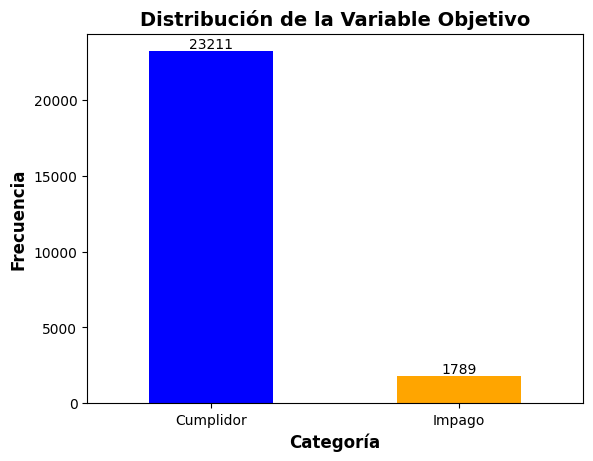

In [54]:
# Gráfica de la distribución de la variable objetivo
y.value_counts().sort_index().plot(kind="bar", color=["blue", "orange"])
plt.title("Distribución de la Variable Objetivo", fontsize=14, fontweight="bold")
plt.xlabel("Categoría", fontsize=12, fontweight="bold")
plt.ylabel("Frecuencia", fontsize=12, fontweight="bold")
for i, value in enumerate(y.value_counts().sort_index()):
    plt.text(i, value, str(value), ha="center", va="bottom", fontsize=10)
plt.xticks(ticks=[0, 1], labels=target_names, rotation=0)
plt.show()

**Desbalance:** solo 1.789 de 25.000 clientes (**7,16 %**) cayeron en impago, frente a 23.211 (92,84 %) cumplidores. Un modelo que aprobara siempre tendría 92,8 % de accuracy sin detectar ningún impago, por lo que el accuracy no sirve como métrica y se estratifica la división de los datos.

# Fase 2: Limpieza y tratamiento de datos (Pipeline)

No hay nulos ni inconsistencias que corregir, pero igualmente se define un `Pipeline` con `ColumnTransformer` (imputación por mediana + `StandardScaler`) para que el flujo sea reutilizable y robusto ante datos nuevos con faltantes. Al estar dentro del pipeline, las transformaciones se ajustan **solo con el conjunto de entrenamiento** (y dentro de cada pliegue en `GridSearchCV`), evitando *data leakage*. El escalado no afecta a un árbol de decisión, pero se incluye por completitud del pipeline.

In [55]:
# Preprocesamiento: imputación (mediana) + escalado, todo ajustado solo con train
preprocesador = ColumnTransformer(
    transformers=[
        (
            "num",
            Pipeline([
                ("imputer", SimpleImputer(strategy="median")),
                ("scaler", StandardScaler()),
            ]),
            list(X.columns),
        )
    ]
)

# Fase 3: Construcción del modelo

## División Train/Test (estratificada)

In [56]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)
print(f"Train: {X_train.shape} | Test: {X_test.shape}")
print(f"% impago en train: {y_train.mean():.4f} | % impago en test: {y_test.mean():.4f}")

Train: (20000, 4) | Test: (5000, 4)
% impago en train: 0.0716 | % impago en test: 0.0716


## Modelo línea base (baseline)

Árbol por defecto (suele sobreajustar al no tener límite de profundidad).

In [57]:
baseline_tree = Pipeline([
    ("prep", preprocesador),
    ("tree", DecisionTreeClassifier(random_state=RANDOM_STATE)),
])
baseline_tree.fit(X_train, y_train)

y_pred_base = baseline_tree.predict(X_test)
y_proba_base = baseline_tree.predict_proba(X_test)[:, 1]

## Optimización con `GridSearchCV`

Se tunean 5 hiperparámetros (`criterion`, `max_depth`, `min_samples_split`, `min_samples_leaf`, `class_weight`) con validación cruzada estratificada de 5 pliegues y `random_state=29`, igual que en el resto de los modelos. La búsqueda se optimiza con **F2-score**, coherente con el costo del negocio (un FN cuesta 7,5 veces un FP).

In [58]:
# F2: pondera el recall el doble que la precisión (un FN cuesta 7,5 veces un FP)
f2_scorer = make_scorer(fbeta_score, beta=2)

param_grid = {
    "tree__criterion": ["gini", "entropy"],        # Criterios de pureza
    "tree__max_depth": [3, 4, 5, 6, 8],            # Control de profundidad para evitar overfitting
    "tree__min_samples_split": [5, 10, 20],        # Mínimo de muestras para dividir un nodo
    "tree__min_samples_leaf": [2, 5, 10],          # Mínimo de muestras en hojas
    "tree__class_weight": [None, "balanced"],      # Peso de las clases (desbalance)
}

grid_search = GridSearchCV(
    estimator=Pipeline([
        ("prep", preprocesador),
        ("tree", DecisionTreeClassifier(random_state=RANDOM_STATE)),
    ]),
    param_grid=param_grid,
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE),
    scoring=f2_scorer,
    n_jobs=-1,
)
grid_search.fit(X_train, y_train)
best_tree = grid_search.best_estimator_

y_pred_opt = best_tree.predict(X_test)
y_proba_opt = best_tree.predict_proba(X_test)[:, 1]

# Fase 4: Evaluación e interpretación de métricas (conjunto de prueba)

**Métricas elegidas: Recall de la clase Impago y F2-score.**

- **Recall (Impago):** mide qué proporción de los clientes que realmente caerán en impago logra detectar el modelo. Cada impago no detectado (FN) cuesta $1.500.000, por lo que es la métrica más ligada a la pérdida financiera.
- **F2-score:** combina recall y precisión dando el doble de peso al recall, reflejando que un FN es mucho más costoso que un FP, pero sin ignorar los créditos viables que se deniegan.
- No se usa accuracy porque con 7,16 % de impagos sería engañosa. El ROC-AUC se muestra solo como referencia.

In [59]:
def metricas(y_true, y_pred, y_proba):
    return {
        "Recall (Impago)": recall_score(y_true, y_pred),
        "F2-score (Impago)": fbeta_score(y_true, y_pred, beta=2),
        "ROC-AUC (referencia)": roc_auc_score(y_true, y_proba),
    }

print("--- HIPERPARÁMETROS ÓPTIMOS ENCONTRADOS ---")
print(grid_search.best_params_)
print(f"F2 promedio en validación cruzada (train): {grid_search.best_score_:.4f}")

resultados = pd.DataFrame({
    "Línea Base": metricas(y_test, y_pred_base, y_proba_base),
    "Optimizado": metricas(y_test, y_pred_opt, y_proba_opt),
}).round(4)
display(resultados)

print("\n--- Comprobación de overfitting (F2 en train vs test) ---")
for nombre, modelo in [("Línea Base", baseline_tree), ("Optimizado", best_tree)]:
    f2_tr = fbeta_score(y_train, modelo.predict(X_train), beta=2)
    f2_te = fbeta_score(y_test, modelo.predict(X_test), beta=2)
    print(f"{nombre}: train = {f2_tr:.4f} | test = {f2_te:.4f}")

print("\n--- REPORTE DE CLASIFICACIÓN (LÍNEA BASE) ---")
print(classification_report(y_test, y_pred_base, target_names=target_names))
print("--- REPORTE DE CLASIFICACIÓN (MODELO OPTIMIZADO) ---")
print(classification_report(y_test, y_pred_opt, target_names=target_names))

--- HIPERPARÁMETROS ÓPTIMOS ENCONTRADOS ---
{'tree__class_weight': 'balanced', 'tree__criterion': 'gini', 'tree__max_depth': 5, 'tree__min_samples_leaf': 2, 'tree__min_samples_split': 5}
F2 promedio en validación cruzada (train): 0.4572


,Línea Base,Optimizado
Recall (Impago),0.3128,0.7682
F2-score (Impago),0.3072,0.4564
ROC-AUC (referencia),0.6264,0.8224



--- Comprobación de overfitting (F2 en train vs test) ---
Línea Base: train = 1.0000 | test = 0.3072
Optimizado: train = 0.4807 | test = 0.4564

--- REPORTE DE CLASIFICACIÓN (LÍNEA BASE) ---
              precision    recall  f1-score   support

   Cumplidor       0.95      0.94      0.94      4642
      Impago       0.29      0.31      0.30       358

    accuracy                           0.90      5000
   macro avg       0.62      0.63      0.62      5000
weighted avg       0.90      0.90      0.90      5000

--- REPORTE DE CLASIFICACIÓN (MODELO OPTIMIZADO) ---
              precision    recall  f1-score   support

   Cumplidor       0.98      0.72      0.83      4642
      Impago       0.17      0.77      0.28       358

    accuracy                           0.72      5000
   macro avg       0.57      0.74      0.56      5000
weighted avg       0.92      0.72      0.79      5000



**Lectura en lenguaje de negocio (conjunto de prueba: 5.000 clientes, 358 impagos reales):**

- El modelo **línea base** detecta solo el 31,3 % de los impagos (recall 0,313) y tiene F2 = 0,307. Además está sobreajustado: F2 = 1,00 en entrenamiento contra 0,307 en prueba, es decir, memorizó los datos y no generaliza.
- El modelo **optimizado** detecta el **76,8 %** de los impagos (recall 0,768) y sube el F2 a 0,456; su desempeño en prueba (0,456) es consistente con el de entrenamiento (0,481), por lo que no hay sobreajuste relevante. El ROC-AUC también mejora de 0,626 a 0,822.
- El costo de esta mejora es una menor precisión: solo 17 % de los clientes marcados como riesgo realmente caen en impago.

## Matriz de confusión

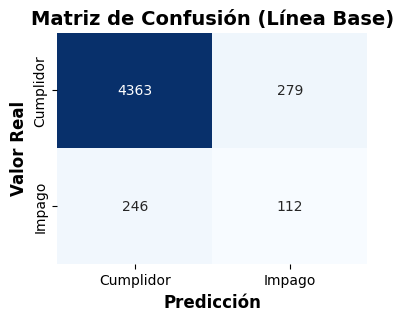

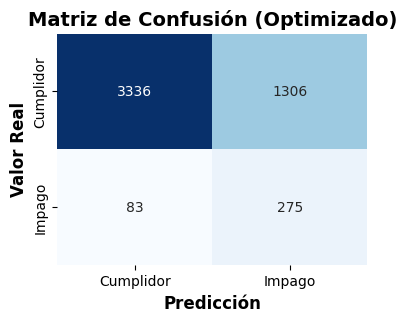

In [60]:
def view_matrix(y_test, y_pred, model_desc="Linea Base"):
    """Muestra la matriz de confusión como mapa de calor."""
    plt.figure(figsize=(4, 3))
    sns.heatmap(
        confusion_matrix(y_test, y_pred),
        annot=True, fmt="d", cmap="Blues",
        xticklabels=target_names, yticklabels=target_names, cbar=False,
    )
    plt.xlabel("Predicción", fontsize=12, fontweight="bold")
    plt.ylabel("Valor Real", fontsize=12, fontweight="bold")
    plt.title(f"Matriz de Confusión ({model_desc})", fontsize=14, fontweight="bold")
    plt.show()

view_matrix(y_test, y_pred_base, "Línea Base")
view_matrix(y_test, y_pred_opt, "Optimizado")

In [61]:
# Impacto financiero de cada modelo sobre el conjunto de prueba
filas = {}
for nombre, pred in [("Línea Base", y_pred_base), ("Optimizado", y_pred_opt)]:
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    filas[nombre] = {
        "VN": tn, "FP": fp, "FN": fn, "VP": tp,
        "Costo FN ($)": fn * COSTO_FN,
        "Costo FP ($)": fp * COSTO_FP,
        "Costo total ($)": fn * COSTO_FN + fp * COSTO_FP,
    }
# Referencia: aprobar todos los créditos (sin modelo)
n_impagos = int(y_test.sum())
filas["Sin modelo (aprobar todo)"] = {
    "VN": 0, "FP": 0, "FN": n_impagos, "VP": 0,
    "Costo FN ($)": n_impagos * COSTO_FN, "Costo FP ($)": 0,
    "Costo total ($)": n_impagos * COSTO_FN,
}
costos = pd.DataFrame(filas).T
costos.style.format("{:,.0f}")

,VN,FP,FN,VP,Costo FN ($),Costo FP ($),Costo total ($)
Línea Base,"4,363",279,246,112,"369,000,000","55,800,000","424,800,000"
Optimizado,"3,336","1,306",83,275,"124,500,000","261,200,000","385,700,000"
Sin modelo (aprobar todo),0,0,358,0,"537,000,000",0,"537,000,000"


### Interpretación de la matriz de confusión: Línea Base

Matriz del modelo línea base (filas = real, columnas = predicción):

| | Pred. Cumplidor | Pred. Impago |
|---|---|---|
| **Real Cumplidor** | VN = 4.363 | FP = 279 |
| **Real Impago** | FN = 246 | VP = 112 |

- **FN = 246:** créditos otorgados a clientes que no pagan. Pérdida de 246 × \$1.500.000 = **\$369.000.000**.
- **FP = 279:** clientes cumplidores a los que se les deniega el crédito. Pérdida de 279 × \$200.000 = **\$55.800.000**.
- **Costo total: \$424.800.000.** El modelo casi no reduce el riesgo: dejar pasar 246 de 358 impagos (68,7 %) hace que el ahorro frente a aprobar todos los créditos (\$537.000.000 de pérdida) sea de apenas ~\$112,2 millones. Es un modelo conservador: acierta mucho con los cumplidores (VN), pero deja pasar la mayoría del riesgo.

### Interpretación de la matriz de confusión: Modelo Optimizado y comparación

Matriz del modelo optimizado:

| | Pred. Cumplidor | Pred. Impago |
|---|---|---|
| **Real Cumplidor** | VN = 3.336 | FP = 1.306 |
| **Real Impago** | FN = 83 | VP = 275 |

- **FN = 83:** baja de 246 a 83 (163 impagos menos otorgados). Pérdida directa de 83 × \$1.500.000 = **\$124.500.000**.
- **FP = 1.306:** sube de 279 a 1.306 (el modelo es mucho más estricto). Costo de oportunidad de 1.306 × \$200.000 = **\$261.200.000**.
- **Costo total: \$385.700.000**, es decir, **\$39,1 millones menos** que la línea base (-9,2 %) y \$151,3 millones menos que aprobar todos los créditos (\$537.000.000).

**Comparación:** el modelo optimizado cambia deliberadamente "créditos perdidos por impago" (muy caros) por "clientes viables rechazados" (más baratos), lo que es coherente con la estructura de costos de la institución. Aun así, rechaza a 1.306 clientes cumplidores (28 % de ellos), un costo comercial relevante que la institución debe evaluar al fijar su política de riesgo.

## Curva ROC-AUC

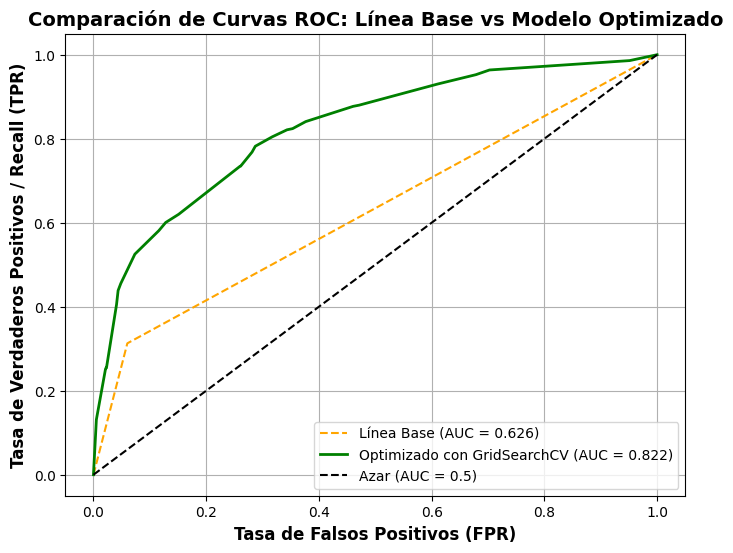

In [62]:
fpr_base, tpr_base, _ = roc_curve(y_test, y_proba_base)
fpr_opt, tpr_opt, _ = roc_curve(y_test, y_proba_opt)
auc_base = roc_auc_score(y_test, y_proba_base)
auc_opt = roc_auc_score(y_test, y_proba_opt)

plt.figure(figsize=(8, 6))
plt.plot(fpr_base, tpr_base, label=f"Línea Base (AUC = {auc_base:.3f})", color="orange", linestyle="--")
plt.plot(fpr_opt, tpr_opt, label=f"Optimizado con GridSearchCV (AUC = {auc_opt:.3f})", color="green", linewidth=2)
plt.plot([0, 1], [0, 1], "k--", label="Azar (AUC = 0.5)")
plt.xlabel("Tasa de Falsos Positivos (FPR)", fontsize=12, fontweight="bold")
plt.ylabel("Tasa de Verdaderos Positivos / Recall (TPR)", fontsize=12, fontweight="bold")
plt.title("Comparación de Curvas ROC: Línea Base vs Modelo Optimizado", fontsize=14, fontweight="bold")
plt.legend(loc="lower right")
plt.grid(True)
plt.show()

**Interpretación de la curva ROC**

- La curva del **modelo optimizado** (AUC = 0,822) queda claramente por encima de la línea base (AUC = 0,626) y de la diagonal del azar (0,5). Esto significa que, si se toma al azar un cliente que cayó en impago y uno que pagó, el modelo optimizado asigna mayor riesgo al que cayó en impago en un 82 % de los casos; la línea base lo logra solo en un 63 %.
- La **línea base** es casi una recta con un único quiebre (alrededor de FPR = 0,06 y TPR = 0,31): al ser un árbol sin límite de profundidad, sus hojas son puras y solo entrega probabilidades de 0 o 1, por lo que no permite graduar el riesgo ni elegir distintos umbrales de decisión.
- El punto de operación del modelo optimizado (FPR ≈ 0,28 y TPR ≈ 0,77) equivale a su matriz de confusión: detecta cerca de 77 de cada 100 impagos, a costa de rechazar cerca de 28 de cada 100 clientes cumplidores. Como la curva es continua, el banco podría mover el umbral para ser más o menos estricto según su apetito de riesgo.

## Visualización del árbol de decisión optimizado

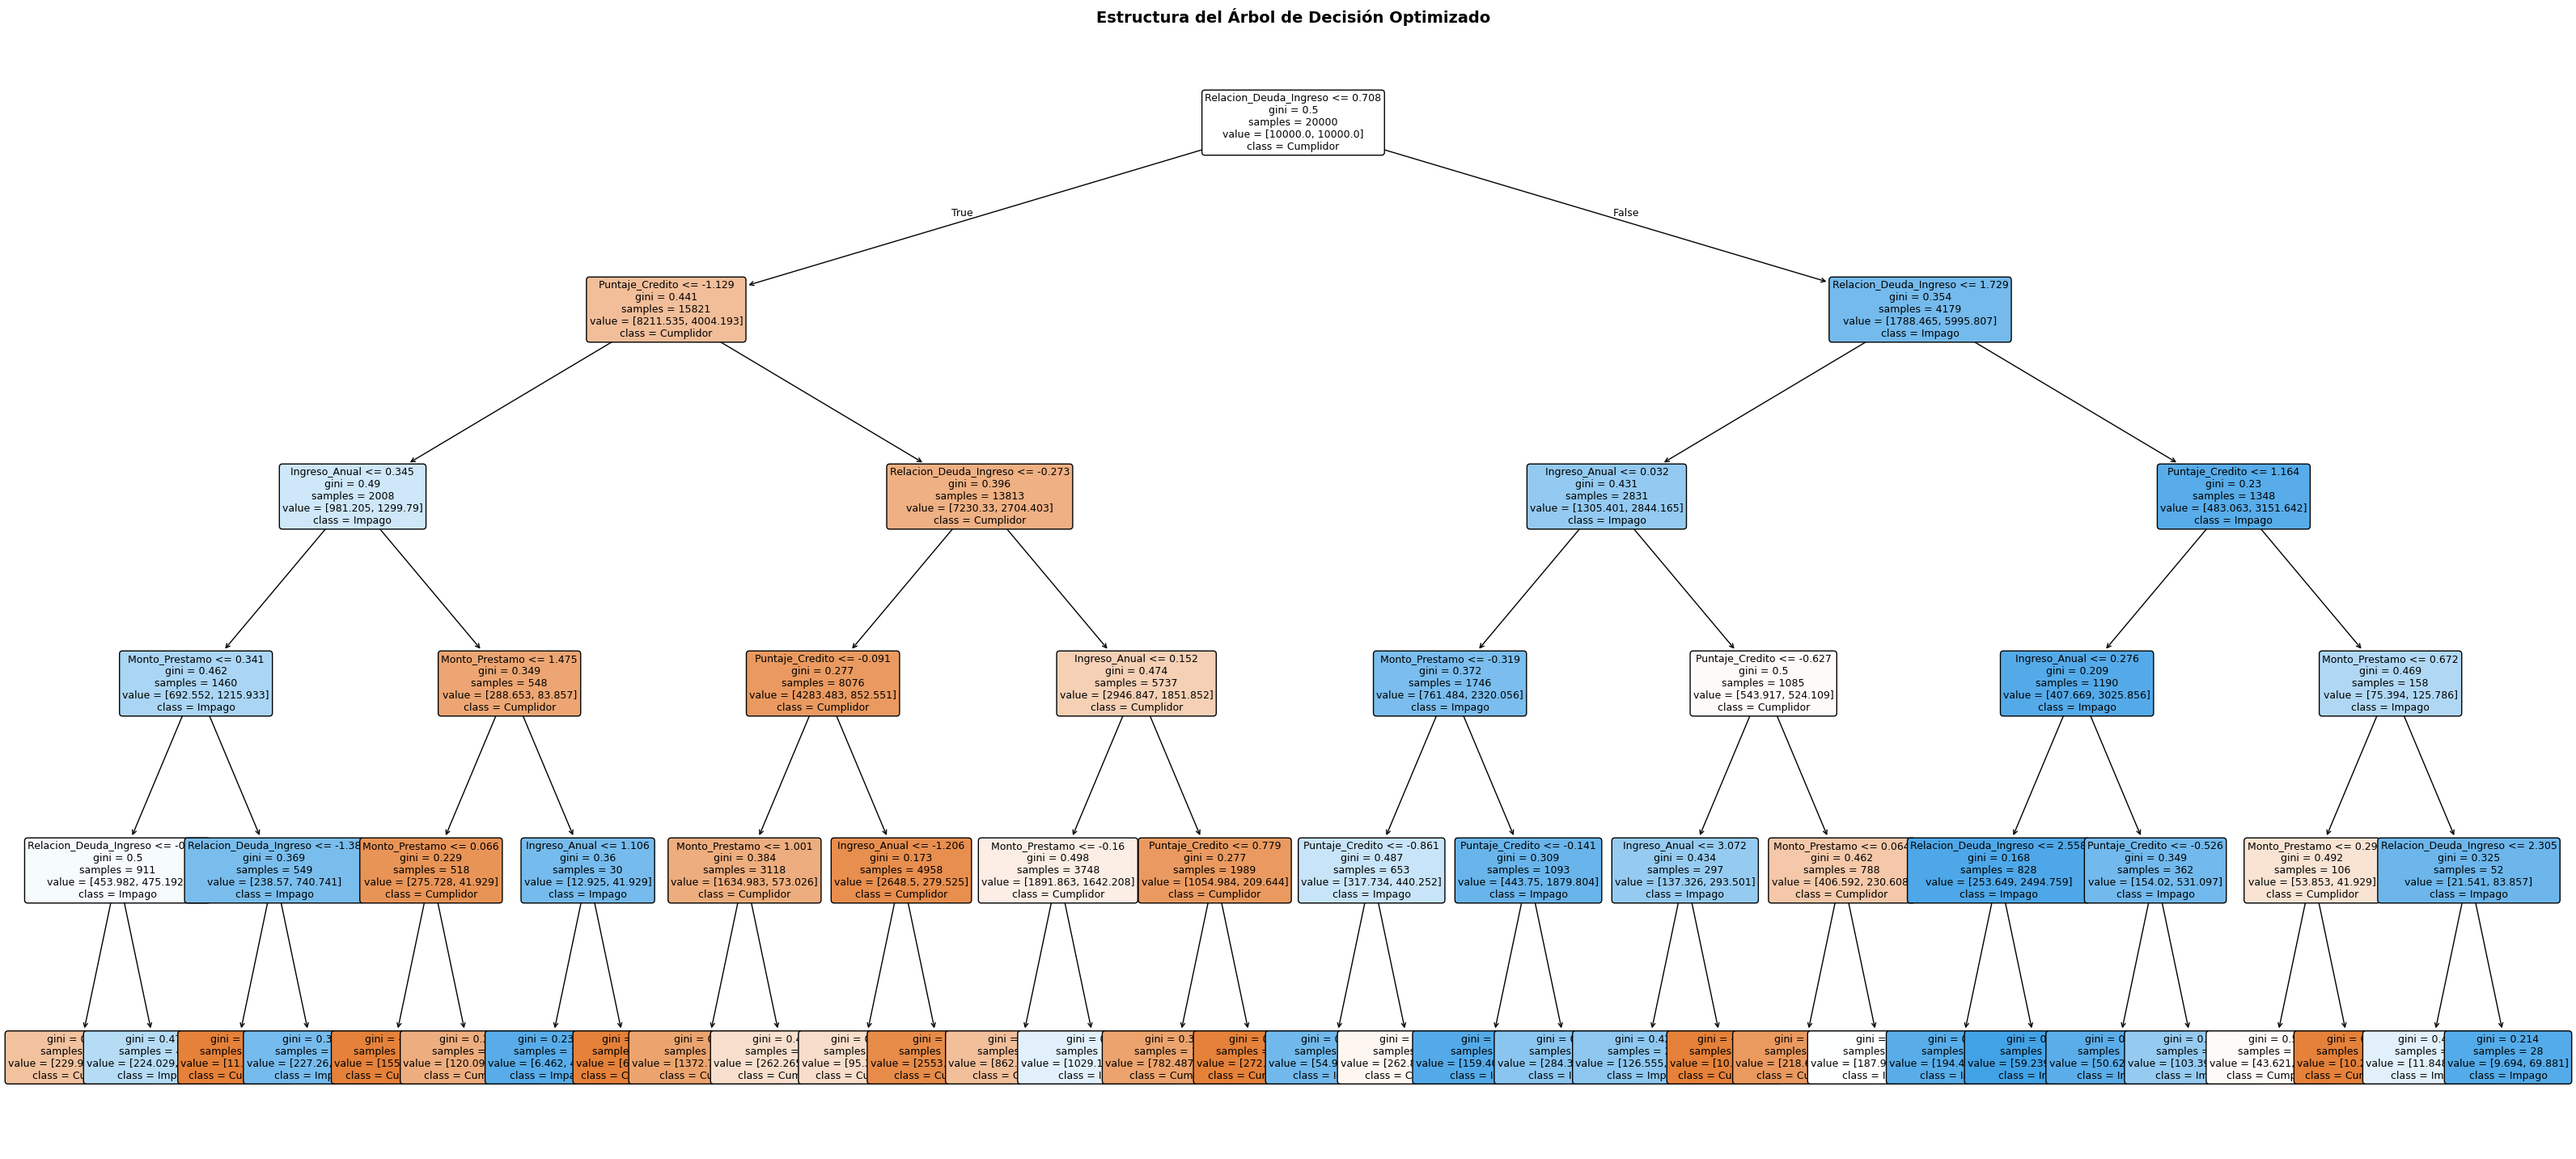

In [63]:
plt.figure(figsize=(40, 18))
plot_tree(
    best_tree.named_steps["tree"],
    feature_names=list(X.columns),
    class_names=target_names,
    filled=True,
    rounded=True,
    fontsize=9,
)
plt.title("Estructura del Árbol de Decisión Optimizado", fontsize=14, fontweight="bold")
plt.show()

**Interpretación del árbol de decisión optimizado**

- El árbol tiene profundidad 5 y 32 hojas, un tamaño acotado que permite explicar cada decisión y evita el sobreajuste de la línea base.
- La **primera división** es por `Relacion_Deuda_Ingreso`: aproximadamente 33,6 % (en el gráfico aparece como 0,7 porque las variables están estandarizadas por el pipeline). Los clientes bajo ese nivel de endeudamiento se clasifican mayoritariamente como **Cumplidor** (nodos naranjos), y los que están sobre ese nivel tienden a **Impago** (nodos azules).
- En la rama de **bajo endeudamiento**, el siguiente criterio es `Puntaje_Credito` (alrededor de 612 puntos): un puntaje bajo, incluso con poca deuda, vuelve a levantar el riesgo.
- En la rama de **alto endeudamiento**, el árbol vuelve a dividir por `Relacion_Deuda_Ingreso` (alrededor de 47 %), y después usa `Ingreso_Anual` y `Puntaje_Credito` para distinguir a los clientes con más capacidad de pago.
- Para el negocio, esto se traduce en reglas simples y auditables: el endeudamiento es el primer filtro, y el puntaje de crédito y el ingreso ayudan a precisar los casos de riesgo intermedio.

## Importancia de las variables (modelo optimizado)

,Variable,Importancia
3,Relacion_Deuda_Ingreso,0.629940
2,Puntaje_Credito,0.155638
0,Ingreso_Anual,0.125613
1,Monto_Prestamo,0.088810


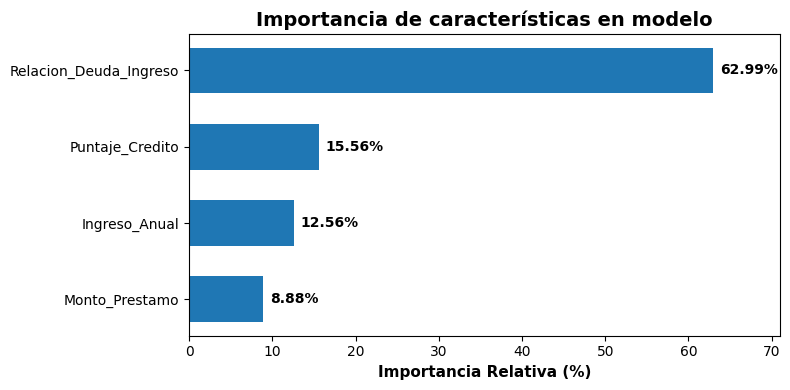

In [64]:
tree_opt = best_tree.named_steps["tree"]
feature_imp_df = pd.DataFrame({
    "Variable": X.columns,
    "Importancia": tree_opt.feature_importances_,
}).sort_values(by="Importancia", ascending=False)
display(feature_imp_df)

fig, ax = plt.subplots(figsize=(8, 4))
sorted_df = feature_imp_df.sort_values("Importancia")
bars = ax.barh(sorted_df["Variable"], sorted_df["Importancia"] * 100, color="#1f77b4", height=0.6)
for bar in bars:
    w = bar.get_width()
    ax.text(w + 0.8, bar.get_y() + bar.get_height() / 2, f"{w:.2f}%", va="center", fontsize=10, fontweight="bold")
ax.set_title("Importancia de características en modelo", fontsize=14, fontweight="bold")
ax.set_xlabel("Importancia Relativa (%)", fontsize=11, fontweight="bold")
ax.set_xlim(0, sorted_df["Importancia"].max() * 100 + 8)
plt.tight_layout()
plt.show()

**Interpretación de la importancia de las variables**

- `Relacion_Deuda_Ingreso` concentra el **63 %** de la importancia del modelo: es, por lejos, la variable que más separa a los clientes que pagan de los que caen en impago.
- Le siguen `Puntaje_Credito` (15,6 %), `Ingreso_Anual` (12,6 %) y `Monto_Prestamo` (8,9 %), que aportan información complementaria.
- Para el banco, la señal más fuerte de riesgo es **cuánto del ingreso del cliente ya está comprometido en deudas**, más que el monto del crédito solicitado. Esto sugiere que la política de evaluación debería poner especial atención al nivel de endeudamiento previo.
- La importancia mide cuánto usa el árbol cada variable para decidir; no implica una relación de causa y efecto.

## Correlación con la variable objetivo

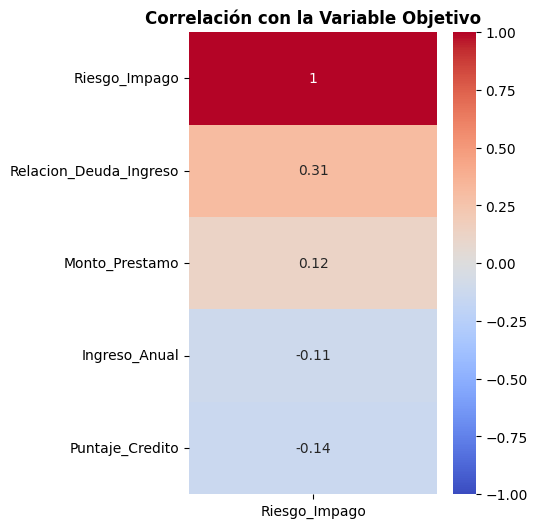

In [65]:
correlation_with_target = data.corr()[[target]].sort_values(by=target, ascending=False)
plt.figure(figsize=(4, 6))
sns.heatmap(correlation_with_target, annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlación con la Variable Objetivo", fontsize=12, fontweight="bold")
plt.show()

**Interpretación de la correlación con la variable objetivo**

- `Relacion_Deuda_Ingreso` tiene la correlación positiva más alta con el impago (0,31): a mayor endeudamiento, mayor probabilidad de impago. Es coherente con ser la variable más importante del árbol.
- `Monto_Prestamo` también se relaciona positivamente (0,12): a mayor monto solicitado, algo más de riesgo.
- `Puntaje_Credito` (-0,14) e `Ingreso_Anual` (-0,11) tienen correlación negativa: puntajes e ingresos más altos se asocian a menor riesgo de impago.
- Ninguna variable supera 0,31 en valor absoluto, es decir, **ninguna explica por sí sola el impago**. Esto justifica usar un modelo que combine varias variables y capture relaciones no lineales, como el árbol de decisión.
- La correlación mide solo relaciones lineales y no implica causalidad.